In [3]:
# ==========================================
# CELL 1: TẢI DỮ LIỆU VÀ THỐNG KÊ TỔNG QUAN
# ==========================================
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Cấu hình thẩm mỹ cho biểu đồ
sns.set_theme(style="whitegrid")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

# Đảm bảo thư mục lưu trữ hình ảnh tồn tại
os.makedirs('../reports/figures', exist_ok=True)

# 1. Đọc dữ liệu thô
df = pd.read_csv('../data/raw/train.csv')

print(f"Tổng số bản ghi: {df.shape[0]} dòng")
print(f"Tổng số thuộc tính: {df.shape[1]} cột")

# 2. Hiển thị 5 dòng đầu tiên
display(df.head())

# 3. Kiểm tra kiểu dữ liệu và missing values
print("\n--- THỐNG KÊ DỮ LIỆU THIẾU (MISSING VALUES) ---")
missing_info = pd.DataFrame({
    'Kiểu dữ liệu': df.dtypes,
    'Số lượng NaN': df.isnull().sum(),
    'Tỷ lệ (%)': (df.isnull().sum() / len(df)) * 100
})
display(missing_info)

# 4. Thống kê mô tả các biến liên tục
print("\n--- THỐNG KÊ MÔ TẢ (DESCRIPTIVE STATISTICS) ---")
display(df.describe().T[['mean', 'std', 'min', '25%', '50%', '75%', 'max']])

Tổng số bản ghi: 2000 dòng
Tổng số thuộc tính: 21 cột


,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,...,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,...,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,...,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,...,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,...,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,...,1208,1212,1411,8,2,15,1,1,0,1



--- THỐNG KÊ DỮ LIỆU THIẾU (MISSING VALUES) ---


,Kiểu dữ liệu,Số lượng NaN,Tỷ lệ (%)
battery_power,int64,0,0.0
blue,int64,0,0.0
clock_speed,float64,0,0.0
dual_sim,int64,0,0.0
fc,int64,0,0.0
four_g,int64,0,0.0
int_memory,int64,0,0.0
m_dep,float64,0,0.0
mobile_wt,int64,0,0.0
n_cores,int64,0,0.0



--- THỐNG KÊ MÔ TẢ (DESCRIPTIVE STATISTICS) ---


,mean,std,min,25%,50%,75%,max
battery_power,1238.51850,439.418206,501.0,851.75,1226.0,1615.25,1998.0
blue,0.49500,0.500100,0.0,0.00,0.0,1.00,1.0
clock_speed,1.52225,0.816004,0.5,0.70,1.5,2.20,3.0
dual_sim,0.50950,0.500035,0.0,0.00,1.0,1.00,1.0
fc,4.30950,4.341444,0.0,1.00,3.0,7.00,19.0
four_g,0.52150,0.499662,0.0,0.00,1.0,1.00,1.0
int_memory,32.04650,18.145715,2.0,16.00,32.0,48.00,64.0
m_dep,0.50175,0.288416,0.1,0.20,0.5,0.80,1.0
mobile_wt,140.24900,35.399655,80.0,109.00,141.0,170.00,200.0
n_cores,4.52050,2.287837,1.0,3.00,4.0,7.00,8.0


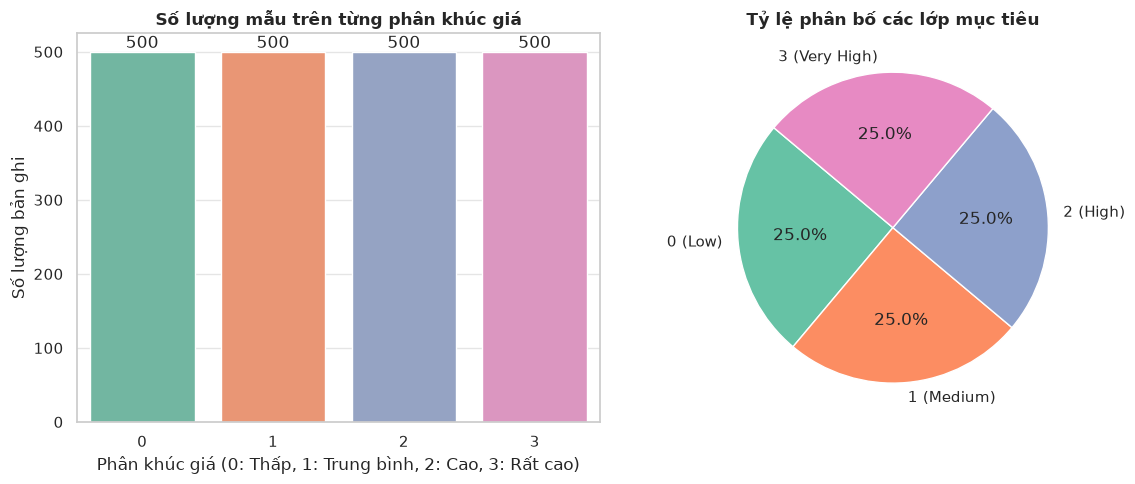

Số lượng bản ghi cụ thể từng lớp:
price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64


In [4]:
# ==========================================
# CELL 2: PHÂN BỐ NHÃN MỤC TIÊU (PRICE RANGE)
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# 1. Biểu đồ cột thể hiện tần số
sns.countplot(
    x='price_range',
    data=df,
    hue='price_range',
    palette='Set2',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Số lượng mẫu trên từng phân khúc giá', fontweight='bold', fontsize=12)
axes[0].set_xlabel('Phân khúc giá (0: Thấp, 1: Trung bình, 2: Cao, 3: Rất cao)')
axes[0].set_ylabel('Số lượng bản ghi')

# Thêm nhãn số lượng trên đầu mỗi cột
for p in axes[0].patches:
    axes[0].annotate(f'{int(p.get_height())}',
                     (p.get_x() + p.get_width() / 2., p.get_height()),
                     ha='center', va='center', xytext=(0, 6), textcoords='offset points')

# 2. Biểu đồ tròn thể hiện tỷ lệ phần trăm
class_counts = df['price_range'].value_counts().sort_index()
axes[1].pie(
    class_counts,
    labels=['0 (Low)', '1 (Medium)', '2 (High)', '3 (Very High)'],
    autopct='%1.1f%%',
    startangle=140,
    colors=sns.color_palette('Set2')
)
axes[1].set_title('Tỷ lệ phân bố các lớp mục tiêu', fontweight='bold', fontsize=12)

plt.tight_layout()
# Lưu biểu đồ vào thư mục reports/figures
plt.savefig('../reports/figures/target_distribution.png', dpi=300)
plt.show()

print("Số lượng bản ghi cụ thể từng lớp:")
print(df['price_range'].value_counts().sort_index())

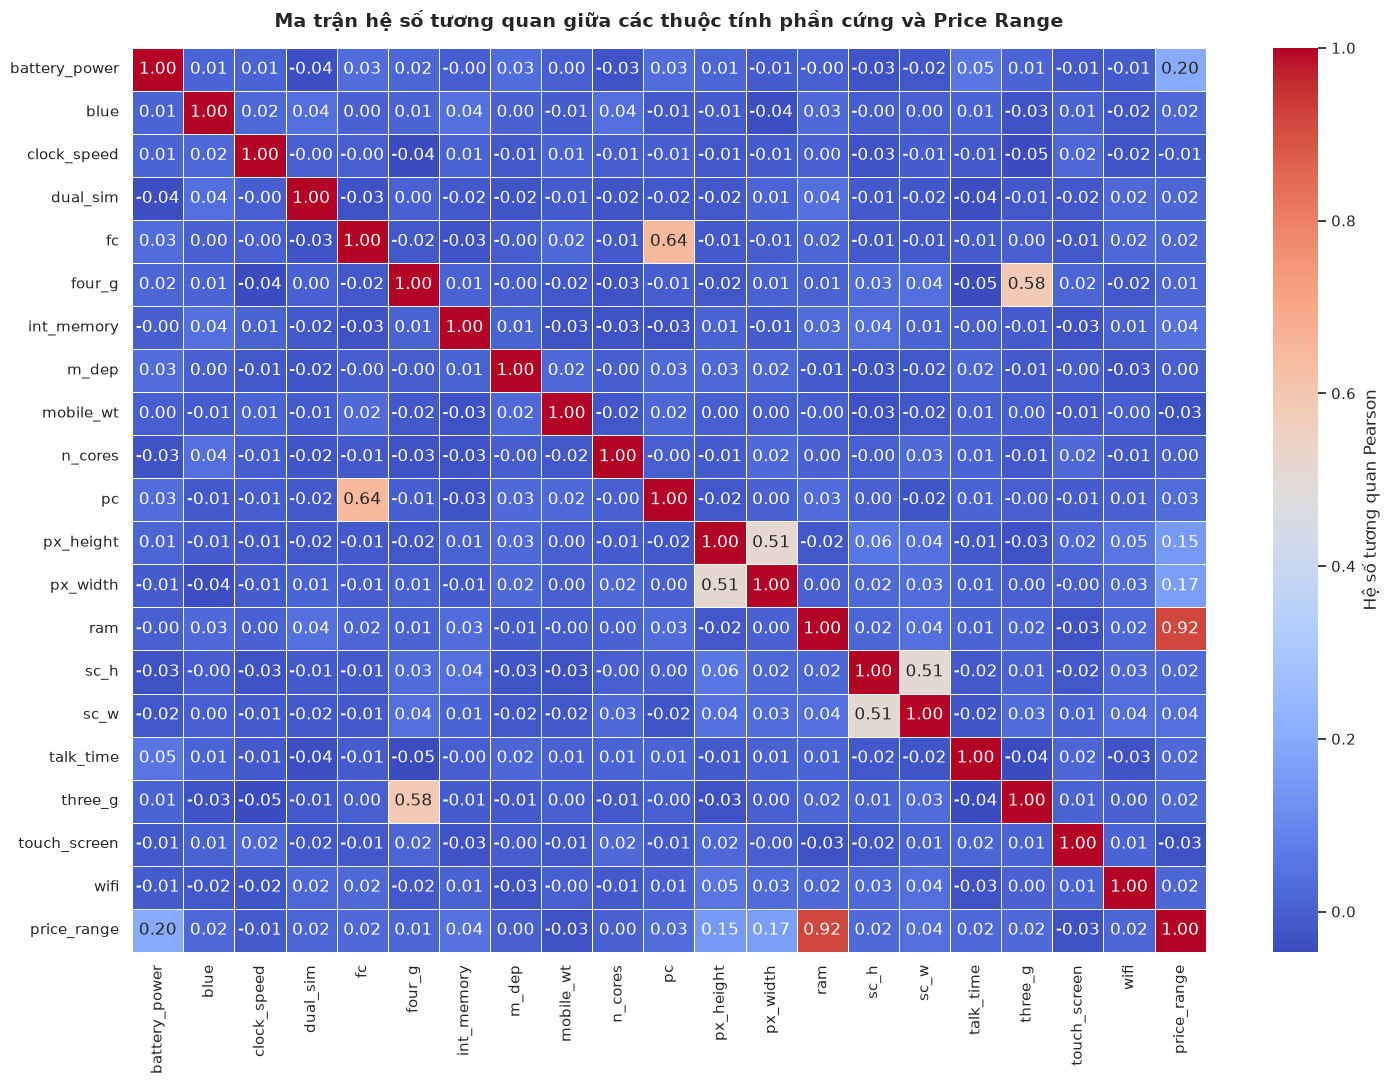

--- XẾP HẠNG MỨC ĐỘ TƯƠNG QUAN VỚI PRICE_RANGE ---
               Correlation
ram               0.917046
battery_power     0.200723
px_width          0.165818
px_height         0.148858
int_memory        0.044435
sc_w              0.038711
pc                0.033599
three_g           0.023611
sc_h              0.022986
fc                0.021998
talk_time         0.021859
blue              0.020573
wifi              0.018785
dual_sim          0.017444
four_g            0.014772
n_cores           0.004399
m_dep             0.000853
clock_speed      -0.006606
mobile_wt        -0.030302
touch_screen     -0.030411


In [5]:
# ==========================================
# CELL 3: MA TRẬN NHIỆT HỆ SỐ TƯƠNG QUAN
# ==========================================
plt.figure(figsize=(15, 11))

corr = df.corr()

# Vẽ heatmap
sns.heatmap(
    corr,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    cbar_kws={'label': 'Hệ số tương quan Pearson'}
)
plt.title('Ma trận hệ số tương quan giữa các thuộc tính phần cứng và Price Range', fontsize=14, fontweight='bold', pad=15)
plt.tight_layout()

# Lưu biểu đồ vào reports/figures/
plt.savefig('../reports/figures/correlation_heatmap.png', dpi=300)
plt.show()

# Liệt kê thứ hạng các thuộc tính tương quan mạnh nhất với price_range
print("--- XẾP HẠNG MỨC ĐỘ TƯƠNG QUAN VỚI PRICE_RANGE ---")
print(corr['price_range'].drop('price_range').sort_values(ascending=False).to_frame(name='Correlation'))

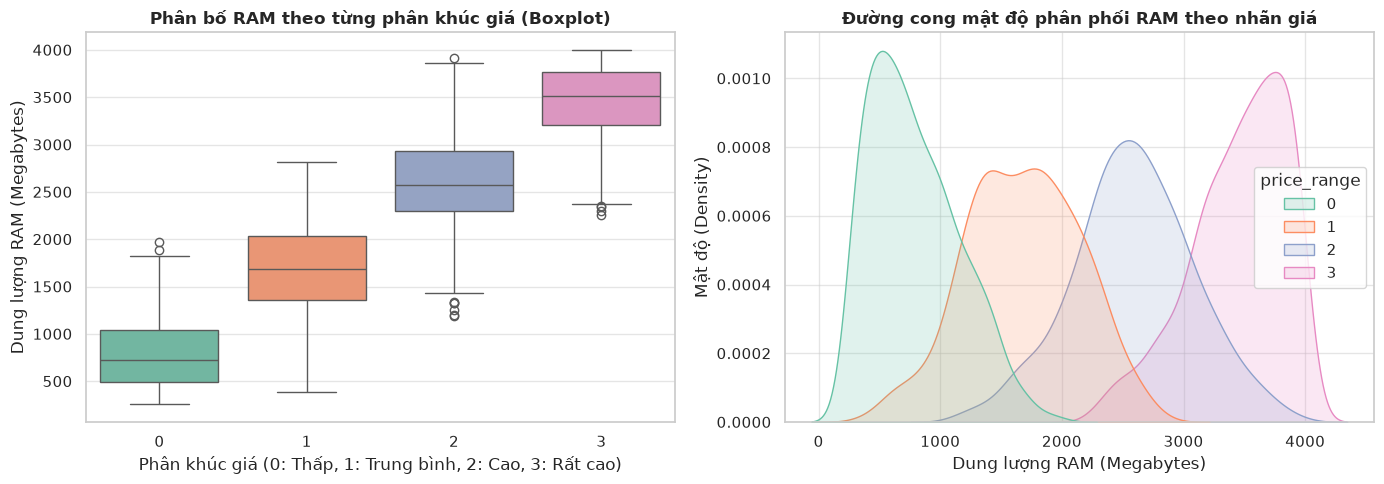

Lượng RAM trung bình theo từng phân khúc:


,mean,median,std,min,max
price_range,,,,,
0,785.314,719.5,362.755397,256,1974
1,1679.490,1686.5,465.850159,387,2811
2,2582.816,2577.0,496.211735,1185,3916
3,3449.232,3509.5,393.019923,2259,3998


In [6]:
# ==========================================
# CELL 4: PHÂN TÍCH CHUYÊN SÂU BIẾN RAM
# ==========================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Boxplot kiểm tra phân bố phân vị và khoảng cách
sns.boxplot(
    x='price_range',
    y='ram',
    data=df,
    hue='price_range',
    palette='Set2',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Phân bố RAM theo từng phân khúc giá (Boxplot)', fontweight='bold')
axes[0].set_xlabel('Phân khúc giá (0: Thấp, 1: Trung bình, 2: Cao, 3: Rất cao)')
axes[0].set_ylabel('Dung lượng RAM (Megabytes)')

# 2. KDE Plot quan sát hình dáng phân phối và độ chồng lấn
sns.kdeplot(
    data=df,
    x='ram',
    hue='price_range',
    common_norm=False,
    palette='Set2',
    fill=True,
    alpha=0.2,
    ax=axes[1]
)
axes[1].set_title('Đường cong mật độ phân phối RAM theo nhãn giá', fontweight='bold')
axes[1].set_xlabel('Dung lượng RAM (Megabytes)')
axes[1].set_ylabel('Mật độ (Density)')

plt.tight_layout()
plt.savefig('../reports/figures/ram_distribution_by_price.png', dpi=300)
plt.show()

# Thống kê lượng RAM trung bình từng phân khúc
print("Lượng RAM trung bình theo từng phân khúc:")
display(df.groupby('price_range')['ram'].agg(['mean', 'median', 'std', 'min', 'max']))

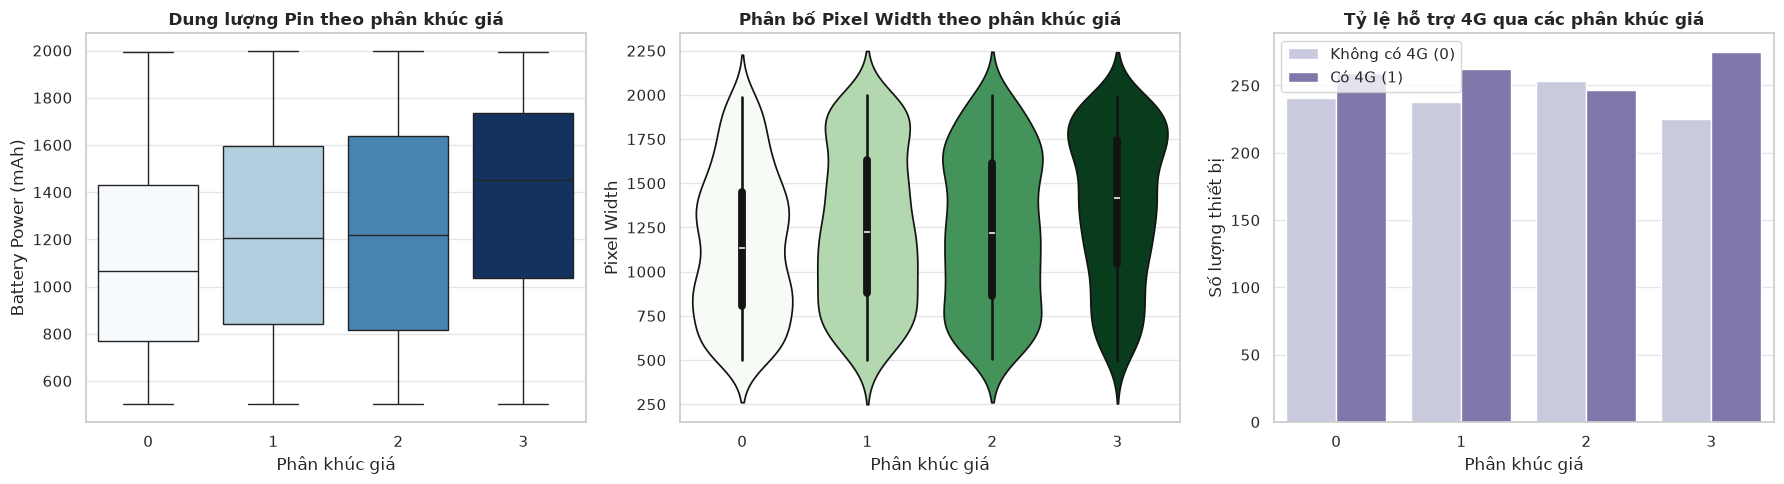

In [7]:
# ==========================================
# CELL 5: PHÂN TÍCH CÁC YẾU TỐ CẤU HÌNH PHỤ TRỢ
# ==========================================
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Khảo sát dung lượng Pin
sns.boxplot(
    x='price_range',
    y='battery_power',
    data=df,
    hue='price_range',
    palette='Blues',
    legend=False,
    ax=axes[0]
)
axes[0].set_title('Dung lượng Pin theo phân khúc giá', fontweight='bold')
axes[0].set_xlabel('Phân khúc giá')
axes[0].set_ylabel('Battery Power (mAh)')

# 2. Mối quan hệ giữa độ phân giải chiều rộng và phân khúc giá
sns.violinplot(
    x='price_range',
    y='px_width',
    data=df,
    hue='price_range',
    palette='Greens',
    legend=False,
    ax=axes[1]
)
axes[1].set_title('Phân bố Pixel Width theo phân khúc giá', fontweight='bold')
axes[1].set_xlabel('Phân khúc giá')
axes[1].set_ylabel('Pixel Width')

# 3. Khảo sát tỷ lệ hỗ trợ mạng 4G
sns.countplot(
    x='price_range',
    hue='four_g',
    data=df,
    palette='Purples',
    ax=axes[2]
)
axes[2].set_title('Tỷ lệ hỗ trợ 4G qua các phân khúc giá', fontweight='bold')
axes[2].set_xlabel('Phân khúc giá')
axes[2].set_ylabel('Số lượng thiết bị')
axes[2].legend(['Không có 4G (0)', 'Có 4G (1)'])

plt.tight_layout()
plt.savefig('../reports/figures/secondary_features_analysis.png', dpi=300)
plt.show()

In [8]:
# ==========================================
# CELL 6: TIỀN XỬ LÝ DỮ LIỆU & FEATURE ENGINEERING
# ==========================================
# 1. Phát hiện các giá trị bằng 0 bất thường về mặt vật lý
invalid_sc_w = (df['sc_w'] == 0).sum()
invalid_px_height = (df['px_height'] == 0).sum()

print(f"Số mẫu có chiều rộng màn hình (sc_w) = 0: {invalid_sc_w}")
print(f"Số mẫu có chiều cao pixel (px_height) = 0: {invalid_px_height}")

# 2. Xử lý làm sạch: Thay thế giá trị 0 bằng trung vị (Median)
df_clean = df.copy()
sc_w_median = df_clean.loc[df_clean['sc_w'] > 0, 'sc_w'].median()
px_h_median = df_clean.loc[df_clean['px_height'] > 0, 'px_height'].median()

df_clean['sc_w'] = df_clean['sc_w'].replace(0, sc_w_median)
df_clean['px_height'] = df_clean['px_height'].replace(0, px_h_median)

# 3. Kỹ nghệ đặc trưng (Feature Engineering): Sinh thuộc tính mới
# - Diện tích điểm ảnh (px_area)
# - Diện tích màn hình vật lý (sc_area tính bằng cm^2)
df_clean['px_area'] = df_clean['px_height'] * df_clean['px_width']
df_clean['sc_area'] = df_clean['sc_h'] * df_clean['sc_w']

print(f"\nKích thước dữ liệu sau khi bổ sung đặc trưng: {df_clean.shape}")

# 4. Xuất file dữ liệu sạch hoàn chỉnh vào data/processed/
output_path = '../data/processed/train_cleaned.csv'
df_clean.to_csv(output_path, index=False)

print(f"✓ Đã lưu thành công tập dữ liệu sạch vào: {output_path}")

# Xem trước 5 dòng của tập dữ liệu mới
display(df_clean[['ram', 'battery_power', 'px_area', 'sc_area', 'price_range']].head())

Số mẫu có chiều rộng màn hình (sc_w) = 0: 180
Số mẫu có chiều cao pixel (px_height) = 0: 2

Kích thước dữ liệu sau khi bổ sung đặc trưng: (2000, 23)
✓ Đã lưu thành công tập dữ liệu sạch vào: ../data/processed/train_cleaned.csv


,ram,battery_power,px_area,sc_area,price_range
0,2549,842,15120.0,63,1
1,2631,1021,1799140.0,51,2
2,2603,563,2167308.0,22,2
3,2769,615,2171776.0,128,2
4,1411,1821,1464096.0,16,1


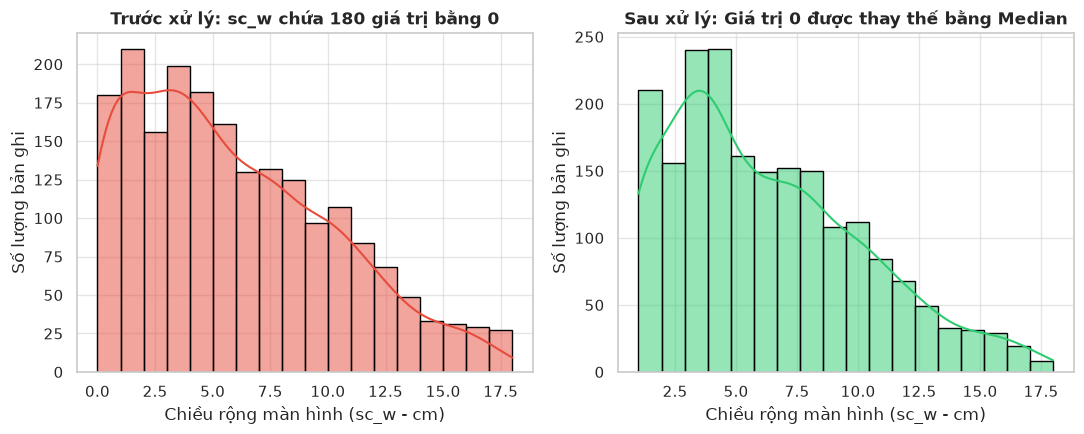

In [9]:
# ==========================================
# CELL: TRỰC QUAN HÓA XỬ LÝ DỊ BIỆT sc_w = 0
# ==========================================
import os
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

# Đảm bảo thư mục lưu ảnh tồn tại
os.makedirs('../reports/figures', exist_ok=True)

# 1. Khởi tạo khung vẽ
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

# 2. Biểu đồ phân phối trước khi xử lý
sns.histplot(
    df['sc_w'],
    bins=18,
    kde=True,
    ax=axes[0],
    color='#e74c3c',
    edgecolor='black',
)
axes[0].set_title(
    'Trước xử lý: sc_w chứa 180 giá trị bằng 0', fontweight='bold'
)
axes[0].set_xlabel('Chiều rộng màn hình (sc_w - cm)')
axes[0].set_ylabel('Số lượng bản ghi')

# 3. Xử lý thay thế giá trị 0 bằng trung vị theo chiều cao màn hình (sc_h)
df_clean = df.copy()
median_sc_w = (
    df_clean[df_clean['sc_w'] > 0].groupby('sc_h')['sc_w'].median().to_dict()
)
df_clean['sc_w'] = df_clean.apply(
    lambda r: median_sc_w.get(r['sc_h'], df_clean['sc_w'].median())
    if r['sc_w'] == 0
    else r['sc_w'],
    axis=1,
)

# 4. Biểu đồ phân phối sau khi xử lý
sns.histplot(
    df_clean['sc_w'],
    bins=18,
    kde=True,
    ax=axes[1],
    color='#2ecc71',
    edgecolor='black',
)
axes[1].set_title(
    'Sau xử lý: Giá trị 0 được thay thế bằng Median', fontweight='bold'
)
axes[1].set_xlabel('Chiều rộng màn hình (sc_w - cm)')
axes[1].set_ylabel('Số lượng bản ghi')

plt.tight_layout()
plt.savefig('../reports/figures/sc_w_cleaned_comparison.png', dpi=300)
plt.show()